# Day 1 — Python and Pandas Basics

In [3]:
import pandas as pd
print("Python & Pandas are Working")

Python & Pandas are Working


In [ ]:
data = {
    "Vehicle Model": ["A1","B1","C1"],
    "UnitSold": [12, 10, 8],
    "Revenue": [360000,300000, 240000],
}

In [ ]:
data

{'Vehicle Model': ['A1', 'B1', 'C1'],
 'UnitSold': [12, 10, 8],
 'Revenue': [360000, 300000, 240000]}

In [ ]:
df = pd.DataFrame(data)

In [ ]:
df

,Vehicle Model,UnitSold,Revenue
0,A1,12,360000
1,B1,10,300000
2,C1,8,240000


In [ ]:
df.shape

(3, 3)

In [ ]:
df.columns

Index(['Vehicle Model', 'UnitSold', 'Revenue'], dtype='object')

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3 entries, 0 to 2
Data columns (total 3 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   Vehicle Model  3 non-null      object
 1   UnitSold       3 non-null      int64 
 2   Revenue        3 non-null      int64 
dtypes: int64(2), object(1)
memory usage: 204.0+ bytes


In [ ]:
df.describe()

,UnitSold,Revenue
count,3.0,3.0
mean,10.0,300000.0
std,2.0,60000.0
min,8.0,240000.0
25%,9.0,270000.0
50%,10.0,300000.0
75%,11.0,330000.0
max,12.0,360000.0


In [ ]:
df["Revenue"]

,Revenue
0,360000
1,300000
2,240000


In [ ]:
df["Revenue"].sum()

np.int64(900000)

In [ ]:
df["UnitSold"].sum()

np.int64(30)

In [ ]:
df["Revenue"].mean()

np.float64(300000.0)

In [ ]:
df["Revenue"].max()

360000

In [ ]:
df["Revenue"].idxmax()

0

In [ ]:
df.loc[0, "Vehicle Model"]

'A1'

In [ ]:
df.sort_values("Revenue", ascending=False)

,Vehicle Model,UnitSold,Revenue,Revenue Per Unit
0,A1,12,360000,30000.0
1,B1,10,300000,30000.0
2,C1,8,240000,30000.0


In [ ]:
df["Revenue"] > 300000

,Revenue
0,True
1,False
2,False


In [ ]:
df[df["Revenue"] > 300000]

,Vehicle Model,UnitSold,Revenue,Revenue Per Unit
0,A1,12,360000,30000.0


In [ ]:
df["Revenue Per Unit"] = df["Revenue"] / df["UnitSold"]

In [ ]:
df

,Vehicle Model,UnitSold,Revenue,Revenue Per Unit
0,A1,12,360000,30000.0
1,B1,10,300000,30000.0
2,C1,8,240000,30000.0


In [ ]:
df[["Vehicle Model", "Revenue Per Unit"]]

,Vehicle Model,Revenue Per Unit
0,A1,30000.0
1,B1,30000.0
2,C1,30000.0


All three vehicle models generate the same revenue per unit at 30000. Therefore the difference in total revenue is caused by unit sold not by the revenue earned per unit.

# Day 2 — Grouping Data with Pandas

In [ ]:
df.groupby("Vehicle Model")["Revenue"].sum()

,Revenue
Vehicle Model,
A1,360000
B1,300000
C1,240000


In [1]:
data2 = {
    "Vehicle Model": ["A1","A1","B1","B1","C1","C1"],
    "Region": ["Delhi","Noida","Delhi","Gurugram","Sonipat","Noida"],
    "UnitSold": [12, 18, 10, 15, 8, 14],
    "Revenue": [360000,540000,300000,450000,240000,420000],
}

In [4]:
df2= pd.DataFrame(data2)

In [5]:
df2

,Vehicle Model,Region,UnitSold,Revenue
0,A1,Delhi,12,360000
1,A1,Noida,18,540000
2,B1,Delhi,10,300000
3,B1,Gurugram,15,450000
4,C1,Sonipat,8,240000
5,C1,Noida,14,420000


In [6]:
df2.groupby(["Vehicle Model"])["Revenue"].sum()

,Revenue
Vehicle Model,
A1,900000
B1,750000
C1,660000


In [13]:
df2.groupby(["Vehicle Model"])["UnitSold"].sum()

,UnitSold
Vehicle Model,
A1,30
B1,25
C1,22


In [14]:
df2.groupby(["Region"])["Revenue"].sum()

,Revenue
Region,
Delhi,660000
Gurugram,450000
Noida,960000
Sonipat,240000


Noida generated the highest revenue at 960,000, while Sonipat generated the lowest revenue at 240,000. The business should investigate the reasons for Sonipat’s lower performance before deciding on promotional or dealer-support actions.

# Day 3 — Sorting and Visualizing Data

In [22]:
regional_revenue = df2.groupby(["Region"])["Revenue"].sum()
regional_revenue.sort_values(ascending=False)

,Revenue
Region,
Noida,960000
Delhi,660000
Gurugram,450000
Sonipat,240000


In [26]:
regional_revenue_df = regional_revenue.sort_values(ascending=False).reset_index()

In [27]:
regional_revenue_df

,Region,Revenue
0,Noida,960000
1,Delhi,660000
2,Gurugram,450000
3,Sonipat,240000


In [28]:
import matplotlib.pyplot as plt

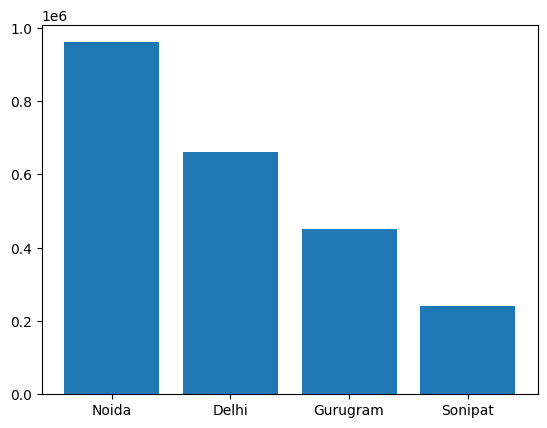

In [36]:
plt.bar(
    regional_revenue_df["Region"],
    regional_revenue_df["Revenue"]
    )
plt.show()

In [37]:
regional_revenue_df["Revenue_Lakhs"] = regional_revenue_df["Revenue"] / 100000

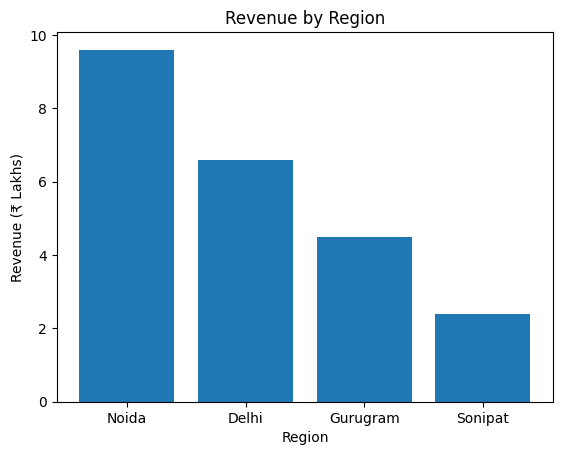

In [38]:
plt.bar(
    regional_revenue_df["Region"],
    regional_revenue_df["Revenue_Lakhs"]
    )
plt.title("Revenue by Region")
plt.xlabel("Region")
plt.ylabel("Revenue (₹ Lakhs)")
plt.show()


Noida has the highest revenue, while Sonipat has the lowest revenue. The business should investigate the reasons for Sonipat’s lower sales, including product demand, product availability, dealer performance, pricing, and promotional activity. After identifying the main cause, the company can take targeted actions such as improving product availability, supporting dealers, or running suitable promotional campaigns in the region.